-   1.开场复盘
    -   1.1开场三问
        -   1.1.1昨天（11/3）学了什么？今天和它是什么关系？
            -   CNN的独立闭环，独立加载复现76.6%，batch不变性，ftt泄露和处理方法
            -   今天将Fashion-MNIST上验证过的【读数据→训练→评价→保存】，迁移到真实超声数据BUS-BRA上
        -   1.1.2今天这块在整条项目链的哪个位置
            -   【数据（BUS-BRA真实超声）→张量→前向→损失→评价→保存】
        -   今天学完，我能多做哪一件具体的事？
            -   ① 从 Zenodo 拿到 BUS-BRA 并说清它的目录结构和标签存储方式
            -   ② 用 Python 读出一张超声图＋它的 BI-RADS 标签并显示
            -   ③ 说清「按病例划分」为什么对乳腺超声分类重要。
    -   1.2复盘
        -   1.2.1泄漏峰值为什么随 T 非单调？
            -   峰值取决于，对应频率最近格点的偏移占df的对比
        -   1.2.2eval()、no_grad()、load_state_dict() 是三件事吗
            -   eval()切换模式，防止BatchNorm 和Dropput
            -   no_grad()不记录梯度节省内存
            -   load_state_dict() 将权重重新填进模型
        -   1.2.3batch 不变性的口径是什么？
            -   评价是按样本加权/平均，不按批次平均，所以batch=64/32/1结果都一致

In [3]:
from pathlib import Path
from collections import Counter

data_dir = Path(r"E:\develop\Graduate_AI\learning-lab\data\BUSBRA")
print("数据目录存在:", data_dir.exists())

# ===== (a) 目录树 =====
def walk(p, depth=0, max_depth=3, max_items=80):
    if depth > max_depth:
        print("  " * depth + "...")
        return
    items = sorted(p.iterdir())
    for it in items[:max_items]:
        if it.is_dir():
            print("  " * depth + f"[dir] {it.name}/")
            walk(it, depth + 1, max_depth, max_items)
        else:
            print("  " * depth + f"{it.name}  ({it.stat().st_size:,} B)")
    if len(items) > max_items:
        print("  " * depth + f"... 还有 {len(items) - max_items} 项未显示")

print("=== 目录树 ===")
walk(data_dir)




数据目录存在: True
=== 目录树 ===
10-fold-cv.csv  (82,728 B)
5-fold-cv.csv  (63,756 B)
bus_data.csv  (180,163 B)
[dir] Images/
  bus_0001-l.png  (44,673 B)
  bus_0001-r.png  (43,272 B)
  bus_0002-l.png  (54,618 B)
  bus_0002-r.png  (55,024 B)
  bus_0003-l.png  (53,786 B)
  bus_0003-r.png  (52,463 B)
  bus_0004-l.png  (48,558 B)
  bus_0004-r.png  (47,370 B)
  bus_0005-l.png  (51,719 B)
  bus_0005-r.png  (49,950 B)
  bus_0006-s.png  (76,784 B)
  bus_0007-l.png  (46,165 B)
  bus_0007-r.png  (45,385 B)
  bus_0008-l.png  (46,610 B)
  bus_0008-r.png  (45,472 B)
  bus_0009-l.png  (45,131 B)
  bus_0009-r.png  (43,053 B)
  bus_0010-l.png  (43,785 B)
  bus_0010-r.png  (42,805 B)
  bus_0011-l.png  (51,656 B)
  bus_0011-r.png  (50,652 B)
  bus_0012-l.png  (43,603 B)
  bus_0012-r.png  (42,391 B)
  bus_0013-l.png  (51,361 B)
  bus_0013-r.png  (47,960 B)
  bus_0014-s.png  (62,252 B)
  bus_0015-s.png  (76,507 B)
  bus_0016-l.png  (54,493 B)
  bus_0016-r.png  (52,965 B)
  bus_0017-s.png  (68,852 B)
  bus_0018-s

In [4]:
# ===== (b) 文件类型统计 =====
exts, total = Counter(), 0
for f in data_dir.rglob("*"):
    if f.is_file():
        exts[f.suffix.lower()] += 1
        total += 1
print("\n=== 文件总数:", total, "===")
print("按扩展名:", dict(exts))


=== 文件总数: 3754 ===
按扩展名: {'.csv': 3, '.txt': 1, '.png': 3750}


In [5]:

# ===== (c) 找标签文件 =====
label_cands = [f for f in data_dir.rglob("*")
               if f.suffix.lower() in {".csv", ".tsv", ".xlsx", ".xls", ".txt", ".json"}]
print("\n=== 可能的标签/元数据文件 ===")
for f in label_cands:
    print(" ", f.relative_to(data_dir))


=== 可能的标签/元数据文件 ===
  10-fold-cv.csv
  5-fold-cv.csv
  bus_data.csv
  LICENSE.txt


-   3754=3个CSV+1个txt+3750张图
    -   3750张PNG=iamge/里1875张超声原图+Masks/里的1875张掩码
    -   mask（掩码）分割任务的标注，所以真正的分类样本数是1875张，所以不能把mask也算到训练集。
-   命名规律暴露了按病理划分的重要性
    -   文件名 bus_0001-l.png、bus_0001-r.png，中间的数字 0001 是病例号，-l/-r 是同一病例的两个视图。
    -   同一个病灶有多张图，如果随机按照图切训练集和验证集，bus_0001-l可能进训练集，bus_0001-r进验证集，这样模型就会记住这个病灶，分数虚高。正确的做法是按病理case整组切分。
-   3个CSV的分工
        -   bus_data.csv主标签，大概率一行一个图
        -   5 10 fold cv csv 官方预先设计好的交叉验证折叠
-   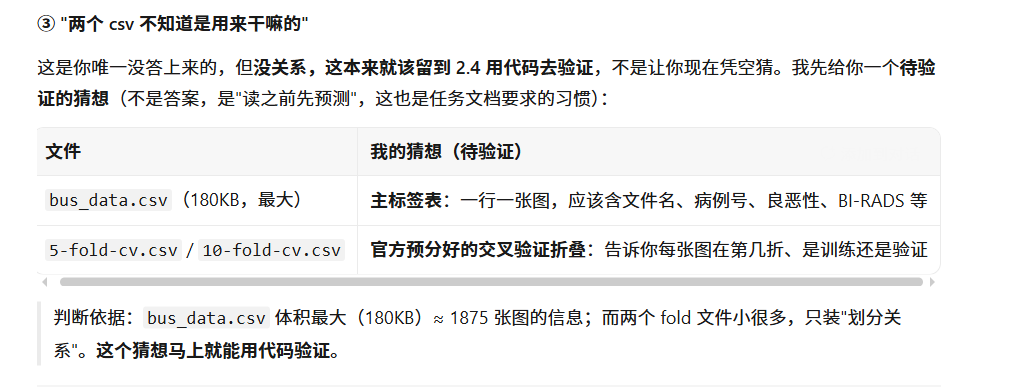

In [6]:
import pandas as pd
from pathlib import Path

data_dir = Path(r"E:\develop\Graduate_AI\learning-lab\data\BUSBRA")

# 逐个读三个 csv 的前 5 行
for name in ["bus_data.csv", "5-fold-cv.csv", "10-fold-cv.csv"]:
    f = data_dir / name
    print("=" * 60)
    print("文件:", name)
    df = pd.read_csv(f, nrows=5)      # 只读前5行，先看结构
    print("列名:", list(df.columns))
    print(df)
    print()


文件: bus_data.csv
列名: ['ID', 'Case', 'Histology', 'Pathology', 'BIRADS', 'Device', 'Width', 'Height', 'Side', 'BBOX']
           ID  Case                  Histology  Pathology  BIRADS  \
0  bus_0001-l     1  invasive ductal carcinoma  malignant       4   
1  bus_0001-r     1  invasive ductal carcinoma  malignant       4   
2  bus_0002-l     2               fibroadenoma     benign       4   
3  bus_0002-r     2               fibroadenoma     benign       4   
4  bus_0003-l     3  invasive ductal carcinoma  malignant       4   

                 Device  Width  Height   Side             BBOX  
0  GE Logiq 7 @10-14MHz    274     353   left   [91,24,103,79]  
1  GE Logiq 7 @10-14MHz    275     353  right   [102,24,82,79]  
2  GE Logiq 7 @10-14MHz    274     371   left  [134,142,88,50]  
3  GE Logiq 7 @10-14MHz    276     371  right  [113,143,68,47]  
4  GE Logiq 7 @10-14MHz    275     372   left  [71,78,126,137]  

文件: 5-fold-cv.csv
列名: ['ID', 'Pathology', 'kFold', 'valid_1', 'valid_2', 'val

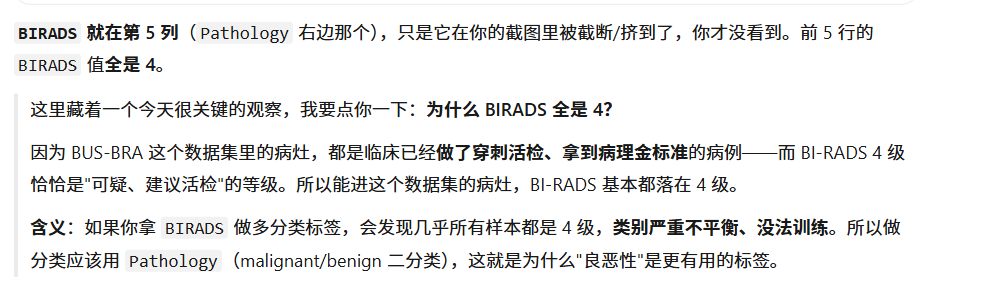
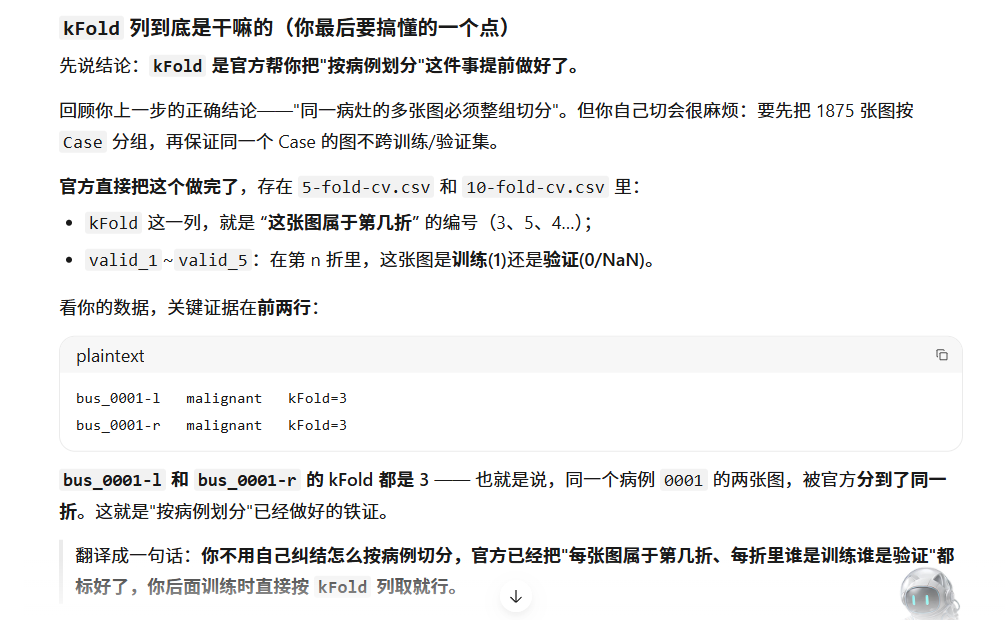

图片总数: 1875
第一张: bus_0001-l.png
颜色模式 mode: L
尺寸 size: (274, 353)


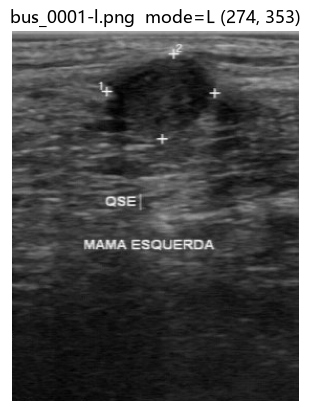

In [8]:
from PIL import Image
import matplotlib.pyplot as plt
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

data_dir = Path(r"E:\develop\Graduate_AI\learning-lab\data\BUSBRA")
img_dir = data_dir / "Images"

img_files = sorted(img_dir.glob("*.png"))
print("图片总数:", len(img_files))

first = img_files[0]
img = Image.open(first)
print("第一张:", first.name)
print("颜色模式 mode:", img.mode)
print("尺寸 size:", img.size)

plt.imshow(img, cmap="gray")
plt.title(f"{first.name}  mode={img.mode} {img.size}")
plt.axis("off")
plt.show()


-   图片是灰度的，一张大小为 宽274 高353
-   图片总数为1875正好符合分类样本1875
-   mode=L 是灰度图，所以smallCNN的第一层：
    -   ToTensor将灰度图转成[1,274,353]——一个通道
    -   所以CNN的第一个卷积层必须写in_channel=1 而不是彩色图的3
    -   灰度图 mode=L →[单通道，H，W] →Conv2d(in_channel=1)

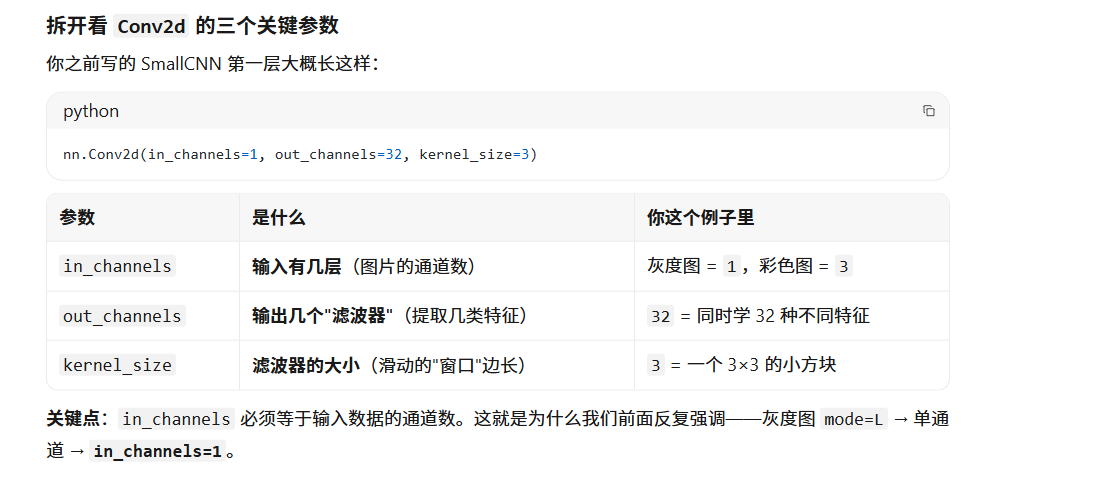
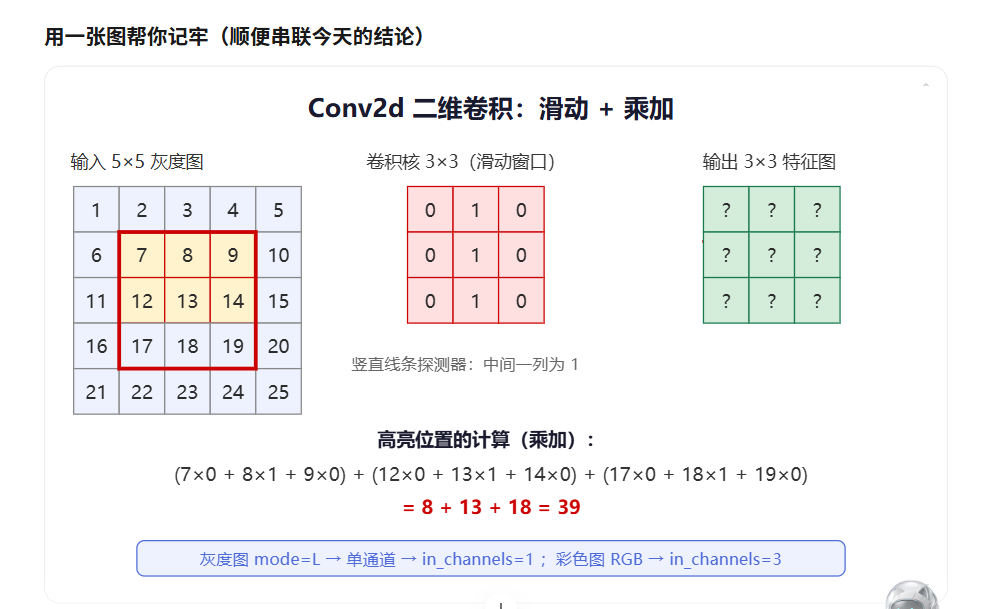